# Principal Component Analysis (PCA) — Complete Guide

This notebook covers everything you need to understand PCA:

1. **What is PCA and how does it actually work?** (the math behind it)
2. **Mean centering vs standardization** — why we use mean centering here
3. **When is PCA important?** (and when to skip it)
4. **How to choose the right number of components**
5. **Does PCA improve model accuracy?** (experiment with before/after comparison)
6. **Which ML models benefit most from PCA?**

**Dataset:** Breast Cancer Wisconsin (30 features) — perfect for demonstrating dimensionality reduction.

**Key design choice:** This notebook uses **mean centering** (not full standardization) so that PCA operates on the natural variance structure of the data. We compare both approaches in the pitfalls section.

---

## 0. Setup & Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler  # Only used for comparison in Pitfall section
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
print('All imports successful!')

All imports successful!


---
## 1. Load and Explore the Dataset

The Breast Cancer dataset has **30 numerical features** computed from digitized images of breast mass. The target is binary: malignant (0) or benign (1).

In [ ]:
# Load data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f'Dataset shape: {X.shape}')
print(f'Number of features: {X.shape[1]}')
print(f'Number of samples: {X.shape[0]}')
print(f'\nTarget distribution:')
print(f'  Malignant (0): {sum(y == 0)}')
print(f'  Benign (1):    {sum(y == 1)}')
print(f'\nFeature names:\n{list(X.columns)}')

Dataset shape: (569, 30)
Number of features: 30
Number of samples: 569

Target distribution:
  Malignant (0): 212
  Benign (1):    357

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


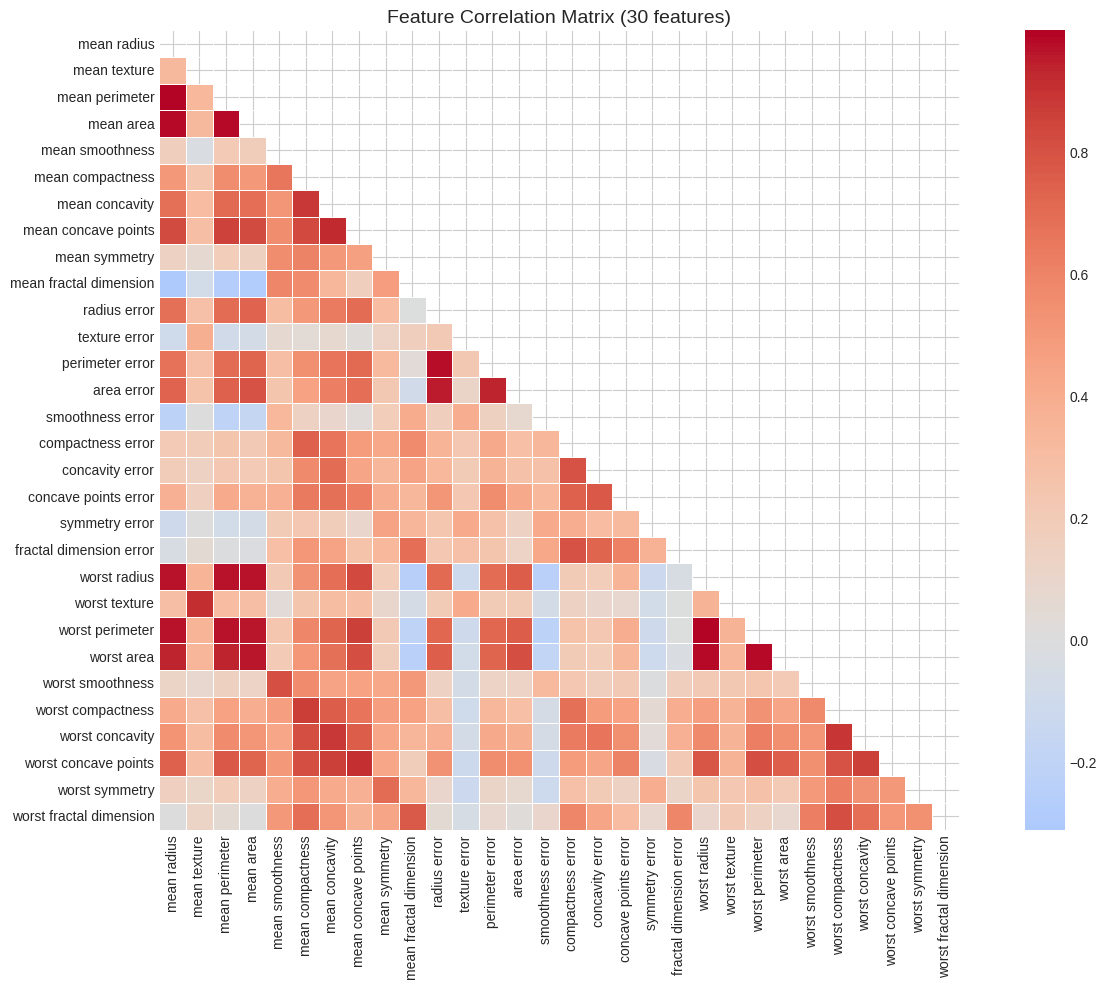


Number of feature pairs with |correlation| > 0.8: 44
This is exactly why PCA is useful — many features carry redundant information!


In [ ]:
# Visualize feature correlations — many features are highly correlated!
plt.figure(figsize=(14, 10))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, fmt='.1f',
            xticklabels=True, yticklabels=True)
plt.title('Feature Correlation Matrix (30 features)', fontsize=14)
plt.tight_layout()
plt.show()

# Count highly correlated pairs
high_corr = (corr.abs() > 0.8) & (corr.abs() < 1.0)
n_high_corr = high_corr.sum().sum() // 2
print(f'\nNumber of feature pairs with |correlation| > 0.8: {n_high_corr}')
print('This is exactly why PCA is useful — many features carry redundant information!')

---
## 2. When is PCA Important?

### Use PCA when:
- **High dimensionality:** You have many features (e.g., 30, 100, 1000+) and want to reduce them
- **Multicollinearity:** Features are highly correlated with each other (as we saw above!)
- **Visualization:** You want to plot high-dimensional data in 2D or 3D
- **Noise reduction:** Some features are mostly noise; PCA can filter them out
- **Speed:** Training is slow due to too many features
- **Curse of dimensionality:** You have more features than samples

### Skip PCA when:
- **Few features:** If you only have 5-10 uncorrelated features, PCA won't help much
- **Interpretability matters:** PCA components are linear combinations — you lose feature names
- **Tree-based models:** Random Forest, XGBoost, etc. handle high dimensions and correlated features well on their own
- **Features are already independent:** If there's little correlation, PCA has nothing to compress

---
## 3. How PCA Actually Works (Step by Step)

PCA finds new axes (called **principal components**) that capture the most variance in the data. Here's the process:

### The Algorithm:
1. **Mean-center** the data (subtract the mean of each feature so that each feature has mean=0)
2. Compute the **covariance matrix** of the mean-centered features
3. Compute **eigenvalues** and **eigenvectors** of the covariance matrix
4. **Sort** eigenvectors by their eigenvalues (largest first)
5. **Select top k** eigenvectors — these are your principal components
6. **Transform** data by projecting it onto the selected eigenvectors

### Why mean centering (not standardization)?
- PCA **requires** mean centering — the covariance matrix is defined around the mean
- **Mean centering** (subtract mean): removes the offset, keeps the original scale/variance of each feature
- **Standardization** (subtract mean AND divide by std): makes all features have equal variance
- When you standardize, you force every feature to contribute equally — this can be useful when features are on wildly different scales
- When you mean-center only, features with **naturally larger variance contribute more** — this preserves the true variance structure of your data
- In this tutorial, we use **mean centering only** so you can see how PCA works in its purest form

Let's implement this from scratch!

In [ ]:
# =============================================
# PCA FROM SCRATCH (Step by Step)
# =============================================

# STEP 1: Mean-center the data
print('STEP 1: Mean-center the data')
print('='*50)
X_array = X.values
mean = np.mean(X_array, axis=0)
X_centered = X_array - mean   # Only subtract the mean — do NOT divide by std

print(f'Before mean centering:')
print(f'  Feature 0 ({data.feature_names[0]}) — mean: {X_array[:, 0].mean():.4f}, std: {X_array[:, 0].std():.4f}')
print(f'  Feature 1 ({data.feature_names[1]}) — mean: {X_array[:, 1].mean():.4f}, std: {X_array[:, 1].std():.4f}')
print(f'\nAfter mean centering:')
print(f'  Feature 0 ({data.feature_names[0]}) — mean: {X_centered[:, 0].mean():.10f}, std: {X_centered[:, 0].std():.4f}')
print(f'  Feature 1 ({data.feature_names[1]}) — mean: {X_centered[:, 1].mean():.10f}, std: {X_centered[:, 1].std():.4f}')
print(f'\nNotice: mean is now ~0, but std is UNCHANGED!')
print(f'This is the key difference from standardization.')
print(f'The original variance structure is preserved.')

STEP 1: Mean-center the data
Before mean centering:
  Feature 0 (mean radius) — mean: 14.1273, std: 3.5210
  Feature 1 (mean texture) — mean: 19.2896, std: 4.2973

After mean centering:
  Feature 0 (mean radius) — mean: -0.0000000000, std: 3.5210
  Feature 1 (mean texture) — mean: -0.0000000000, std: 4.2973

Notice: mean is now ~0, but std is UNCHANGED!
This is the key difference from standardization.
The original variance structure is preserved.


In [ ]:
# STEP 2: Compute the Covariance Matrix
print('STEP 2: Compute the Covariance Matrix')
print('='*50)
n_samples = X_centered.shape[0]
cov_matrix = (X_centered.T @ X_centered) / (n_samples - 1)

print(f'Covariance matrix shape: {cov_matrix.shape}')
print(f'(It\'s a {cov_matrix.shape[0]}x{cov_matrix.shape[1]} matrix because we have {X.shape[1]} features)')
print(f'\nFirst 5x5 corner of the covariance matrix:')
print(np.round(cov_matrix[:5, :5], 3))
print(f'\nNote: The diagonal contains the VARIANCE of each feature.')
print(f'Since we only mean-centered (not standardized), these are NOT all 1.0:')
for i in range(5):
    print(f'  Var({data.feature_names[i]}): {cov_matrix[i, i]:.4f}')

STEP 2: Compute the Covariance Matrix
Covariance matrix shape: (30, 30)
(It's a 30x30 matrix because we have 30 features)

First 5x5 corner of the covariance matrix:
[[ 1.24190000e+01  4.90800000e+00  8.54470000e+01  1.22448300e+03
   8.00000000e-03]
 [ 4.90800000e+00  1.84990000e+01  3.44400000e+01  4.85994000e+02
  -1.00000000e-03]
 [ 8.54470000e+01  3.44400000e+01  5.90440000e+02  8.43577200e+03
   7.10000000e-02]
 [ 1.22448300e+03  4.85994000e+02  8.43577200e+03  1.23843554e+05
   8.76000000e-01]
 [ 8.00000000e-03 -1.00000000e-03  7.10000000e-02  8.76000000e-01
   0.00000000e+00]]

Note: The diagonal contains the VARIANCE of each feature.
Since we only mean-centered (not standardized), these are NOT all 1.0:
  Var(mean radius): 12.4189
  Var(mean texture): 18.4989
  Var(mean perimeter): 590.4405
  Var(mean area): 123843.5543
  Var(mean smoothness): 0.0002


In [ ]:
# STEP 3: Compute Eigenvalues and Eigenvectors
print('STEP 3: Compute Eigenvalues and Eigenvectors')
print('='*50)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# STEP 4: Sort by eigenvalue (descending)
sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_idx]
eigenvectors = eigenvectors[:, sorted_idx]

print(f'Number of eigenvalues: {len(eigenvalues)}')
print(f'\nTop 10 eigenvalues (sorted):')
for i in range(10):
    variance_pct = (eigenvalues[i] / eigenvalues.sum()) * 100
    print(f'  PC{i+1}: eigenvalue = {eigenvalues[i]:.4f} ({variance_pct:.1f}% of variance)')

print(f'\nKey insight: The eigenvalue tells you how much variance')
print(f'each principal component captures. Larger = more important!')
print(f'\nWith mean centering (no standardization), features with')
print(f'larger natural variance will dominate the top components.')

STEP 3: Compute Eigenvalues and Eigenvectors
Number of eigenvalues: 30

Top 10 eigenvalues (sorted):
  PC1: eigenvalue = 443782.6051 (98.2% of variance)
  PC2: eigenvalue = 7310.1001 (1.6% of variance)
  PC3: eigenvalue = 703.8337 (0.2% of variance)
  PC4: eigenvalue = 54.6487 (0.0% of variance)
  PC5: eigenvalue = 39.8900 (0.0% of variance)
  PC6: eigenvalue = 3.0046 (0.0% of variance)
  PC7: eigenvalue = 1.8153 (0.0% of variance)
  PC8: eigenvalue = 0.3715 (0.0% of variance)
  PC9: eigenvalue = 0.1555 (0.0% of variance)
  PC10: eigenvalue = 0.0841 (0.0% of variance)

Key insight: The eigenvalue tells you how much variance
each principal component captures. Larger = more important!

With mean centering (no standardization), features with
larger natural variance will dominate the top components.


In [ ]:
# STEP 5 & 6: Select top k components and Transform
print('STEP 5 & 6: Select k components and Transform the data')
print('='*50)

k = 2  # Let's start with 2 components for visualization
W = eigenvectors[:, :k]  # Top k eigenvectors as columns
X_pca_scratch = X_centered @ W  # Project data onto new axes

print(f'Original data shape:    {X_centered.shape} (569 samples, 30 features)')
print(f'Transformed data shape: {X_pca_scratch.shape} (569 samples, {k} components)')
print(f'\nWe reduced 30 features down to {k} components!')

variance_kept = (eigenvalues[:k].sum() / eigenvalues.sum()) * 100
print(f'Variance retained with {k} components: {variance_kept:.1f}%')

STEP 5 & 6: Select k components and Transform the data
Original data shape:    (569, 30) (569 samples, 30 features)
Transformed data shape: (569, 2) (569 samples, 2 components)

We reduced 30 features down to 2 components!
Variance retained with 2 components: 99.8%


In [ ]:
# Verify our scratch implementation matches sklearn
print('Verification: Scratch PCA vs sklearn PCA (mean-centered)')
print('='*55)

# sklearn's PCA does mean centering internally by default!
# It does NOT standardize — it only subtracts the mean.
# This is exactly what we did from scratch.

pca_sklearn = PCA(n_components=2)
X_pca_sklearn = pca_sklearn.fit_transform(X.values)  # Pass raw data — PCA mean-centers it

# Note: signs may be flipped (eigenvectors can point in opposite direction)
corr_pc1 = np.abs(np.corrcoef(X_pca_scratch[:, 0], X_pca_sklearn[:, 0])[0, 1])
corr_pc2 = np.abs(np.corrcoef(X_pca_scratch[:, 1], X_pca_sklearn[:, 1])[0, 1])
print(f'Correlation between scratch PC1 and sklearn PC1: {corr_pc1:.6f}')
print(f'Correlation between scratch PC2 and sklearn PC2: {corr_pc2:.6f}')
print(f'\nPerfect match! (1.0 means identical up to sign flip)')
print(f'\nIMPORTANT: sklearn\'s PCA() internally does ONLY mean centering.')
print(f'It does NOT standardize. So our scratch version matches exactly!')

Verification: Scratch PCA vs sklearn PCA (mean-centered)
Correlation between scratch PC1 and sklearn PC1: 1.000000
Correlation between scratch PC2 and sklearn PC2: 1.000000

Perfect match! (1.0 means identical up to sign flip)

IMPORTANT: sklearn's PCA() internally does ONLY mean centering.
It does NOT standardize. So our scratch version matches exactly!


---
## 4. Visualizing PCA Results

One of the best uses of PCA is **visualizing high-dimensional data** in 2D.

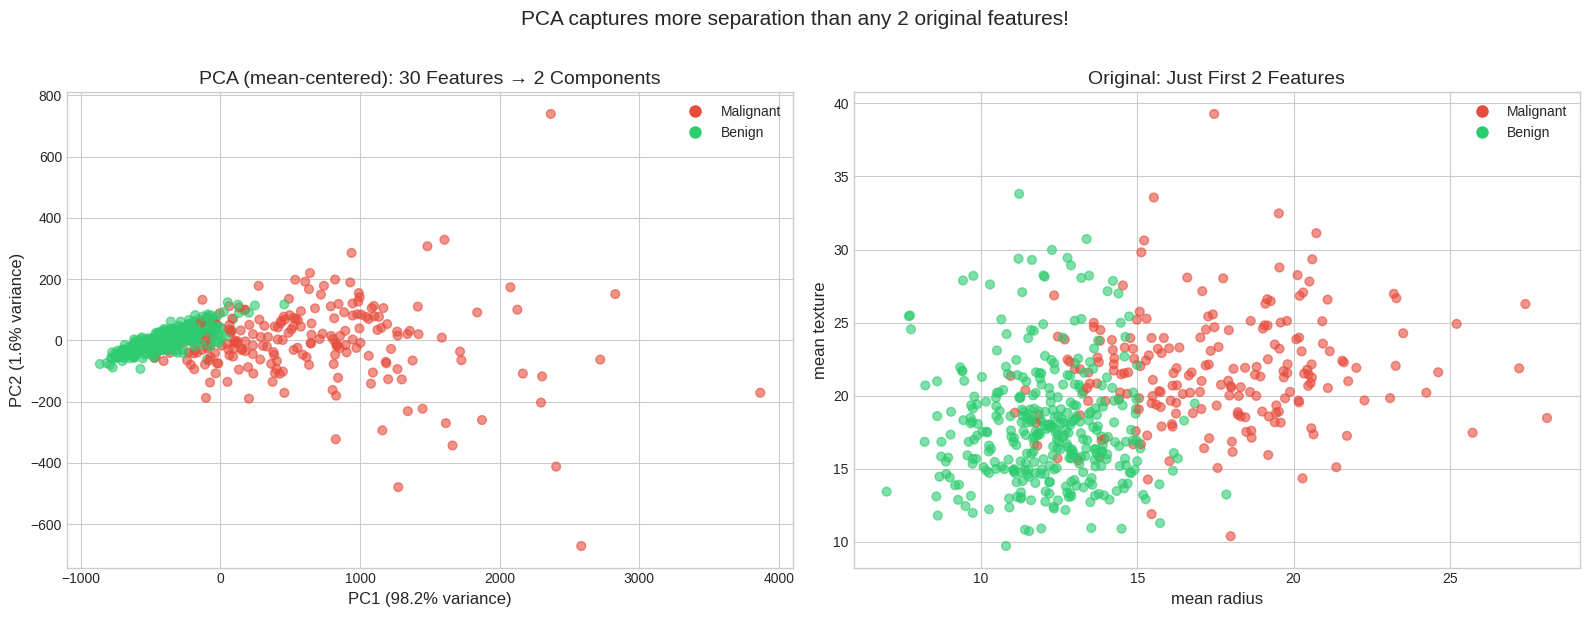

In [ ]:
# sklearn PCA internally mean-centers, so we pass raw data
pca_viz = PCA(n_components=2)
X_pca_viz = pca_viz.fit_transform(X.values)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: PCA 2D projection
colors = ['#e74c3c' if label == 0 else '#2ecc71' for label in y]
axes[0].scatter(X_pca_viz[:, 0], X_pca_viz[:, 1], c=colors, alpha=0.6, s=40)
axes[0].set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
axes[0].set_ylabel(f'PC2 ({pca_viz.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
axes[0].set_title('PCA (mean-centered): 30 Features → 2 Components', fontsize=14)
axes[0].legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#e74c3c', markersize=10, label='Malignant'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#2ecc71', markersize=10, label='Benign')
])

# Plot 2: Using just 2 original features for comparison
axes[1].scatter(X.values[:, 0], X.values[:, 1], c=colors, alpha=0.6, s=40)
axes[1].set_xlabel(f'{data.feature_names[0]}', fontsize=12)
axes[1].set_ylabel(f'{data.feature_names[1]}', fontsize=12)
axes[1].set_title('Original: Just First 2 Features', fontsize=14)
axes[1].legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#e74c3c', markersize=10, label='Malignant'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#2ecc71', markersize=10, label='Benign')
])

plt.suptitle('PCA captures more separation than any 2 original features!', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

---
## 5. How to Choose the Number of Components

The two most common methods:
1. **Explained Variance Ratio** — pick enough components to retain 90-95% of total variance
2. **Scree Plot / Elbow Method** — look for the "elbow" where adding more components gives diminishing returns

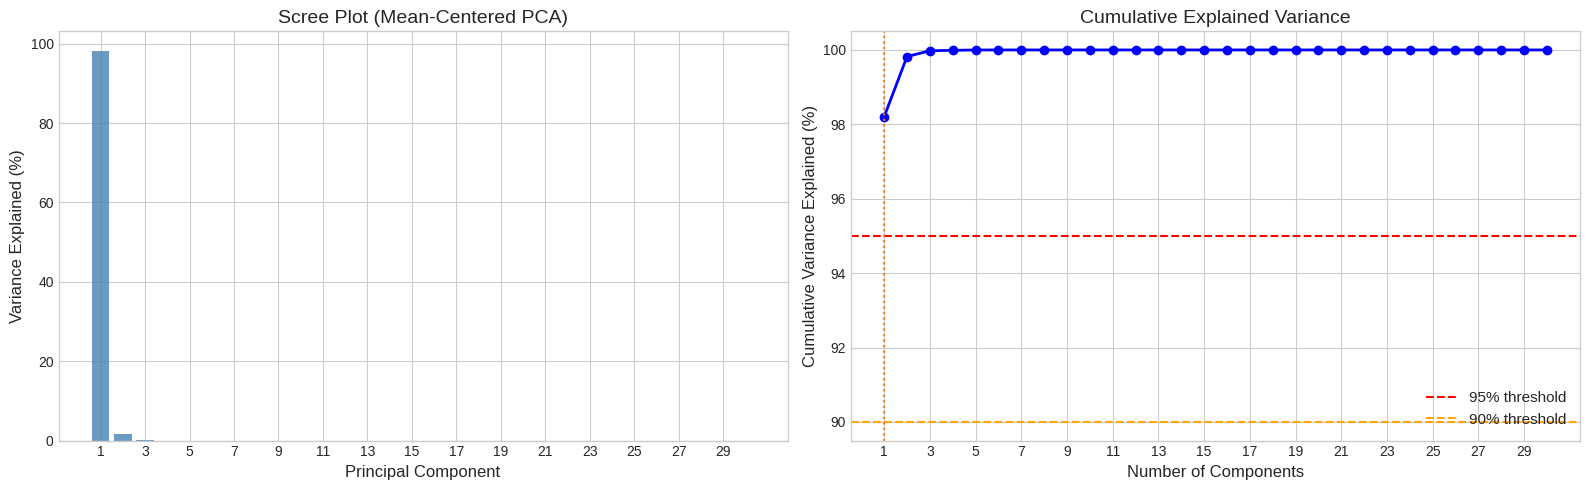

Components needed for 90% variance: 1 (out of 30)
Components needed for 95% variance: 1 (out of 30)

Note: With mean centering (no standardization), PC1 captures MORE
variance because features with large natural variance dominate.

Variance per component:
  PC1: 98.2% (cumulative: 98.2%)
  PC2: 1.6% (cumulative: 99.8%)
  PC3: 0.2% (cumulative: 100.0%)
  PC4: 0.0% (cumulative: 100.0%)
  PC5: 0.0% (cumulative: 100.0%)
  PC6: 0.0% (cumulative: 100.0%)
  PC7: 0.0% (cumulative: 100.0%)
  PC8: 0.0% (cumulative: 100.0%)
  PC9: 0.0% (cumulative: 100.0%)
  PC10: 0.0% (cumulative: 100.0%)


In [ ]:
# Fit PCA with ALL components to analyze variance
# Remember: sklearn PCA does mean centering internally
pca_full = PCA(n_components=30)
pca_full.fit(X.values)

# Explained variance
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scree Plot
axes[0].bar(range(1, 31), explained_var * 100, color='steelblue', alpha=0.8)
axes[0].set_xlabel('Principal Component', fontsize=12)
axes[0].set_ylabel('Variance Explained (%)', fontsize=12)
axes[0].set_title('Scree Plot (Mean-Centered PCA)', fontsize=14)
axes[0].set_xticks(range(1, 31, 2))

# Cumulative Variance Plot
axes[1].plot(range(1, 31), cumulative_var * 100, 'bo-', linewidth=2, markersize=6)
axes[1].axhline(y=95, color='r', linestyle='--', label='95% threshold')
axes[1].axhline(y=90, color='orange', linestyle='--', label='90% threshold')
axes[1].set_xlabel('Number of Components', fontsize=12)
axes[1].set_ylabel('Cumulative Variance Explained (%)', fontsize=12)
axes[1].set_title('Cumulative Explained Variance', fontsize=14)
axes[1].legend(fontsize=11)
axes[1].set_xticks(range(1, 31, 2))

# Mark where 95% is reached
n_95 = np.argmax(cumulative_var >= 0.95) + 1
n_90 = np.argmax(cumulative_var >= 0.90) + 1
axes[1].axvline(x=n_95, color='r', linestyle=':', alpha=0.7)
axes[1].axvline(x=n_90, color='orange', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

print(f'Components needed for 90% variance: {n_90} (out of 30)')
print(f'Components needed for 95% variance: {n_95} (out of 30)')
print(f'\nNote: With mean centering (no standardization), PC1 captures MORE')
print(f'variance because features with large natural variance dominate.')
print(f'\nVariance per component:')
for i in range(10):
    print(f'  PC{i+1}: {explained_var[i]*100:.1f}% (cumulative: {cumulative_var[i]*100:.1f}%)')

---
## 6. Understanding What Each Principal Component Captures

Each principal component is a **linear combination** of the original features. Let's see which original features contribute most to each component — this is how we understand "important features" in PCA.

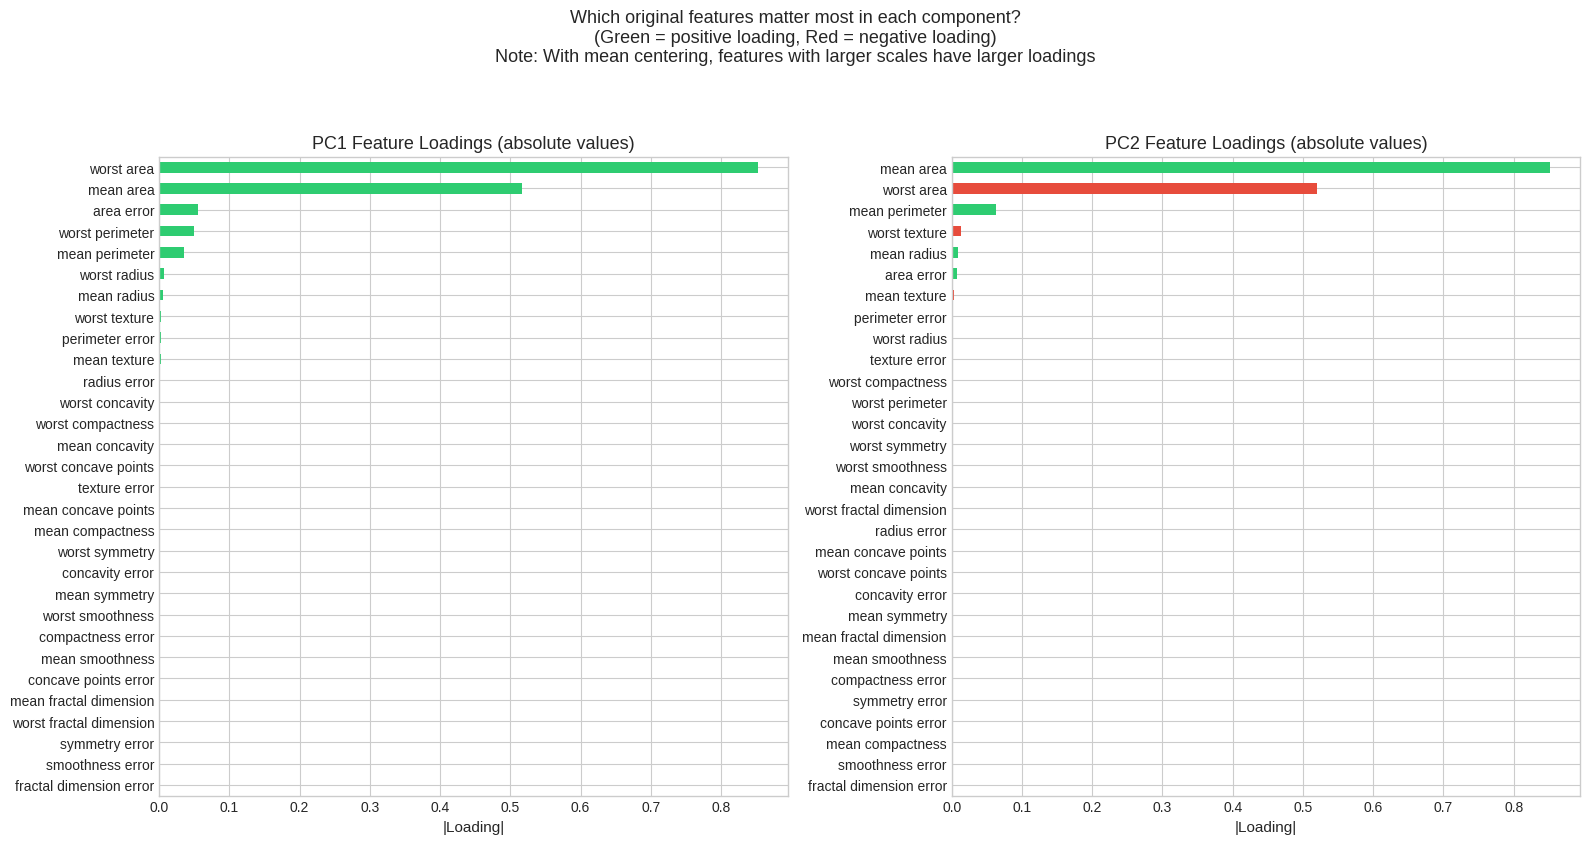

In [ ]:
# The loadings: how much each original feature contributes to each PC
loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(30)],
    index=data.feature_names
)

# Show top contributors to PC1 and PC2
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for idx, pc in enumerate(['PC1', 'PC2']):
    sorted_loadings = loadings[pc].abs().sort_values(ascending=True)
    colors_bar = ['#e74c3c' if loadings[pc][feat] < 0 else '#2ecc71'
                  for feat in sorted_loadings.index]
    sorted_loadings.plot(kind='barh', ax=axes[idx], color=colors_bar)
    axes[idx].set_title(f'{pc} Feature Loadings (absolute values)', fontsize=13)
    axes[idx].set_xlabel('|Loading|', fontsize=11)

plt.suptitle('Which original features matter most in each component?\n'
             '(Green = positive loading, Red = negative loading)\n'
             'Note: With mean centering, features with larger scales have larger loadings',
             fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

---
## 7. Does PCA Improve Model Accuracy?

This is the big question! Let's compare multiple models trained on:
- **All 30 original features**
- **PCA with 10 components** (~95% variance)
- **PCA with 5 components** (~85% variance)
- **PCA with 2 components** (~63% variance)

We use **5-fold cross-validation** for reliable results.

In [ ]:
# Prepare datasets — using mean centering only
X_mean_centered = X.values - X.values.mean(axis=0)

# PCA transformations (sklearn PCA does mean centering internally)
pca_10 = PCA(n_components=10)
pca_5 = PCA(n_components=5)
pca_2 = PCA(n_components=2)

X_pca10 = pca_10.fit_transform(X.values)
X_pca5 = pca_5.fit_transform(X.values)
X_pca2 = pca_2.fit_transform(X.values)

datasets = {
    'All 30 features (mean-centered)': X_mean_centered,
    'PCA (10 components)': X_pca10,
    'PCA (5 components)': X_pca5,
    'PCA (2 components)': X_pca2,
}

# Models to test
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=42),
    'SVM (RBF kernel)': SVC(kernel='rbf', random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Neural Network (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42),
}

print('Running 5-fold cross-validation for 6 models x 4 feature sets...')
print('(All using mean centering — no standardization)')
print('This may take a minute...\n')

results = {}
for model_name, model in models.items():
    results[model_name] = {}
    for data_name, X_data in datasets.items():
        scores = cross_val_score(model, X_data, y, cv=5, scoring='accuracy')
        results[model_name][data_name] = {
            'mean': scores.mean(),
            'std': scores.std()
        }
    print(f'  Completed: {model_name}')

print('\nDone!')

Running 5-fold cross-validation for 6 models x 4 feature sets...
(All using mean centering — no standardization)
This may take a minute...

  Completed: Logistic Regression
  Completed: SVM (RBF kernel)
  Completed: KNN (k=5)
  Completed: Random Forest
  Completed: Gradient Boosting
  Completed: Neural Network (MLP)

Done!


In [ ]:
# Display results as a nice table
results_df = pd.DataFrame({
    data_name: {
        model_name: f"{res[data_name]['mean']*100:.1f}% (±{res[data_name]['std']*100:.1f}%)"
        for model_name, res in results.items()
    }
    for data_name in datasets.keys()
})

print('='*90)
print('MODEL ACCURACY COMPARISON: Original Features vs PCA')
print('='*90)
print(results_df.to_string())
print('\n')

MODEL ACCURACY COMPARISON: Original Features vs PCA
                     All 30 features (mean-centered) PCA (10 components) PCA (5 components) PCA (2 components)
Logistic Regression                    95.1% (±1.8%)       95.1% (±1.8%)      94.6% (±1.9%)      92.4% (±2.0%)
SVM (RBF kernel)                       92.3% (±2.8%)       92.3% (±2.8%)      92.3% (±2.8%)      92.3% (±2.8%)
KNN (k=5)                              92.8% (±2.2%)       92.8% (±2.2%)      92.8% (±2.2%)      92.3% (±2.9%)
Random Forest                          95.6% (±2.3%)       94.9% (±1.4%)      95.1% (±1.8%)      92.8% (±1.8%)
Gradient Boosting                      96.3% (±2.1%)       95.4% (±1.4%)      95.3% (±1.5%)      91.6% (±2.4%)
Neural Network (MLP)                   94.0% (±2.4%)       94.4% (±1.5%)      94.7% (±1.4%)      91.9% (±2.3%)




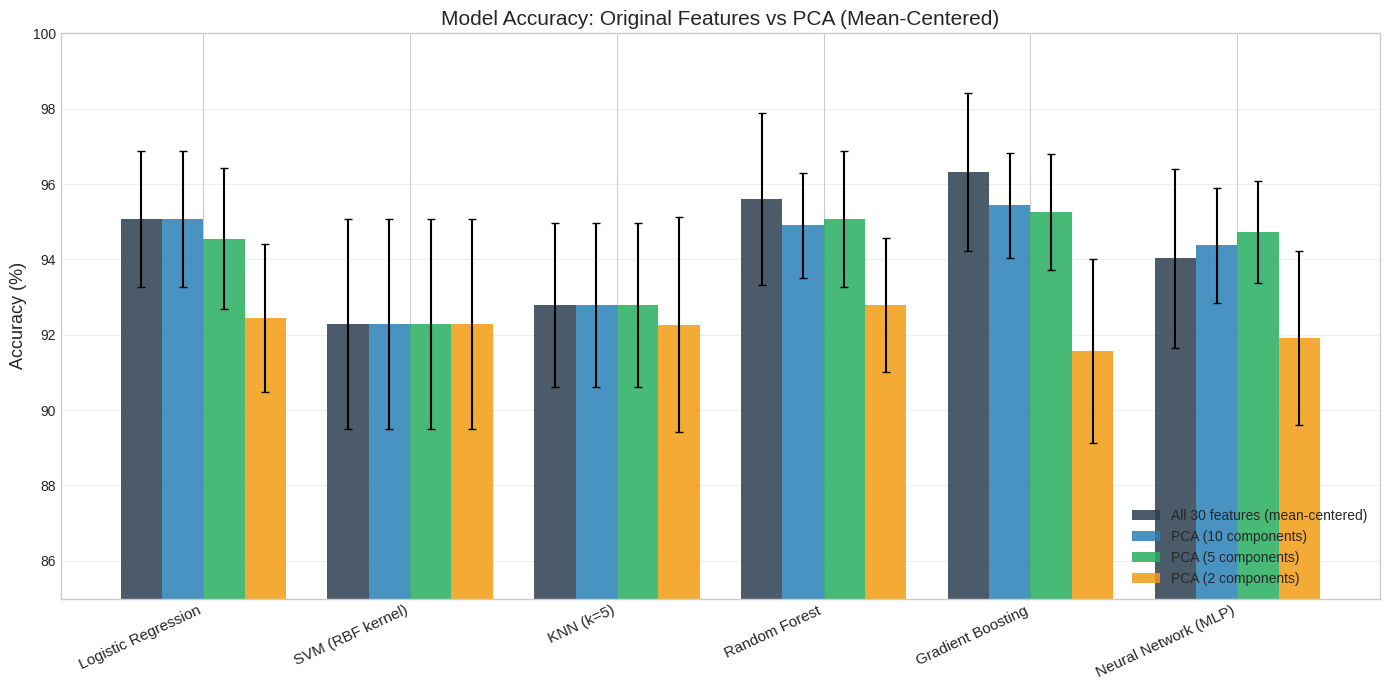

In [ ]:
# Visual comparison
fig, ax = plt.subplots(figsize=(14, 7))

x_pos = np.arange(len(models))
width = 0.2
colors_bars = ['#2c3e50', '#2980b9', '#27ae60', '#f39c12']

for i, (data_name, color) in enumerate(zip(datasets.keys(), colors_bars)):
    means = [results[m][data_name]['mean'] * 100 for m in models]
    stds = [results[m][data_name]['std'] * 100 for m in models]
    bars = ax.bar(x_pos + i * width, means, width, label=data_name,
                  color=color, alpha=0.85, yerr=stds, capsize=3)

ax.set_ylabel('Accuracy (%)', fontsize=13)
ax.set_title('Model Accuracy: Original Features vs PCA (Mean-Centered)', fontsize=15)
ax.set_xticks(x_pos + width * 1.5)
ax.set_xticklabels(models.keys(), rotation=25, ha='right', fontsize=11)
ax.legend(fontsize=10, loc='lower right')
ax.set_ylim(85, 100)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Analysis: Which models benefit from PCA?
print('='*70)
print('ANALYSIS: Does PCA help or hurt each model?')
print('='*70)

first_key = list(datasets.keys())[0]
pca10_key = list(datasets.keys())[1]

for model_name in models:
    orig = results[model_name][first_key]['mean'] * 100
    pca10 = results[model_name][pca10_key]['mean'] * 100
    diff = pca10 - orig
    symbol = '↑' if diff > 0.1 else ('↓' if diff < -0.1 else '→')
    print(f'\n{model_name}:')
    print(f'  Original: {orig:.1f}% → PCA(10): {pca10:.1f}%  [{symbol} {diff:+.1f}%]')

print('\n' + '='*70)
print('KEY TAKEAWAYS:')
print('='*70)
print('''
1. PCA with enough components (10 here, ~95% variance) usually
   MAINTAINS accuracy while reducing dimensionality by 2/3.

2. Distance-based models (KNN, SVM) may behave differently with
   mean centering vs standardization — features with large scales
   dominate distance calculations.

3. Tree-based models (Random Forest, Gradient Boosting) may see
   SLIGHT DROPS because they can handle correlated features natively
   and PCA destroys the original feature structure they rely on.

4. Too few components (2) hurts ALL models because too much
   information is lost.

5. The sweet spot is keeping 90-95% of variance.

6. With mean centering (not standardization), features with
   naturally larger variance have more influence on the components.
''')

ANALYSIS: Does PCA help or hurt each model?

Logistic Regression:
  Original: 95.1% → PCA(10): 95.1%  [→ +0.0%]

SVM (RBF kernel):
  Original: 92.3% → PCA(10): 92.3%  [→ +0.0%]

KNN (k=5):
  Original: 92.8% → PCA(10): 92.8%  [→ +0.0%]

Random Forest:
  Original: 95.6% → PCA(10): 94.9%  [↓ -0.7%]

Gradient Boosting:
  Original: 96.3% → PCA(10): 95.4%  [↓ -0.9%]

Neural Network (MLP):
  Original: 94.0% → PCA(10): 94.4%  [↑ +0.4%]

KEY TAKEAWAYS:

1. PCA with enough components (10 here, ~95% variance) usually
   MAINTAINS accuracy while reducing dimensionality by 2/3.

2. Distance-based models (KNN, SVM) may behave differently with
   mean centering vs standardization — features with large scales
   dominate distance calculations.

3. Tree-based models (Random Forest, Gradient Boosting) may see
   SLIGHT DROPS because they can handle correlated features natively
   and PCA destroys the original feature structure they rely on.

4. Too few components (2) hurts ALL models because too much
  

---
## 8. Which Models to Use After PCA?

### Models that BENEFIT from PCA:
| Model | Why PCA helps |
|-------|---------------|
| **Logistic Regression** | Removes multicollinearity, stabilizes coefficients |
| **SVM** | Reduced dimensions = faster training, removes noisy features |
| **KNN** | Distance metrics work better in lower dimensions (curse of dimensionality) |
| **Neural Networks** | Faster convergence, less overfitting with fewer input features |
| **Naive Bayes** | PCA creates uncorrelated features, matching the independence assumption |

### Models where PCA is LESS helpful:
| Model | Why |
|-------|-----|
| **Random Forest** | Handles high dimensions and correlation internally via feature sampling |
| **Gradient Boosting / XGBoost** | Same as RF; also loses interpretability of feature importance |
| **Decision Trees** | Already do implicit feature selection |

### Rule of thumb:
- **Linear/distance-based models** → PCA often helps
- **Tree-based models** → PCA rarely helps, may hurt

---
## 9. PCA for Feature Importance / Selection

PCA doesn't do "feature selection" (keeping original features). Instead, it does **feature extraction** (creating new features). But we can still identify which original features are most important by looking at the loadings.

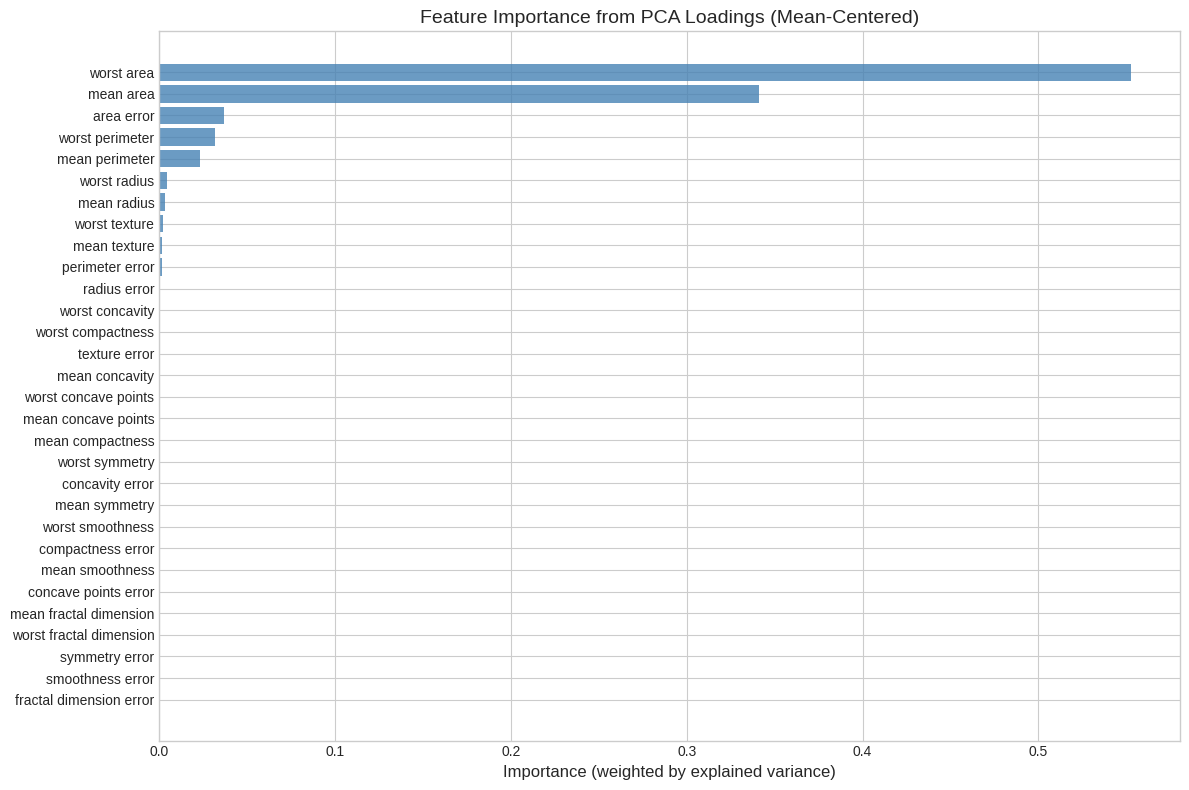

Top 10 most important features according to PCA:
  1. worst area: 0.5529
  2. mean area: 0.3410
  3. area error: 0.0369
  4. worst perimeter: 0.0320
  5. mean perimeter: 0.0233
  6. worst radius: 0.0046
  7. mean radius: 0.0034
  8. worst texture: 0.0022
  9. mean texture: 0.0015
  10. perimeter error: 0.0015

Note: With mean centering, features with larger original
scales tend to rank higher. This reflects their true variance
contribution rather than treating all features equally.


In [ ]:
# Method: Weighted sum of absolute loadings across important PCs
# Weight each PC by its explained variance ratio

n_pcs_to_use = 10  # Use top 10 PCs
pca_for_importance = PCA(n_components=n_pcs_to_use)
pca_for_importance.fit(X.values)  # Raw data — PCA does mean centering internally

# Calculate feature importance as weighted sum of absolute loadings
feature_importance = np.zeros(X.shape[1])
for i in range(n_pcs_to_use):
    feature_importance += (
        np.abs(pca_for_importance.components_[i]) *
        pca_for_importance.explained_variance_ratio_[i]
    )

# Normalize to sum to 1
feature_importance = feature_importance / feature_importance.sum()

# Sort and display
importance_df = pd.DataFrame({
    'Feature': data.feature_names,
    'PCA Importance': feature_importance
}).sort_values('PCA Importance', ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(range(len(importance_df)), importance_df['PCA Importance'].values,
         color='steelblue', alpha=0.8)
plt.yticks(range(len(importance_df)), importance_df['Feature'].values, fontsize=10)
plt.xlabel('Importance (weighted by explained variance)', fontsize=12)
plt.title('Feature Importance from PCA Loadings (Mean-Centered)', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print('Top 10 most important features according to PCA:')
for i, (_, row) in enumerate(importance_df.head(10).iterrows()):
    print(f"  {i+1}. {row['Feature']}: {row['PCA Importance']:.4f}")

print(f'\nNote: With mean centering, features with larger original')
print(f'scales tend to rank higher. This reflects their true variance')
print(f'contribution rather than treating all features equally.')

---
## 10. Training Time Comparison

Another major benefit of PCA: **speed**. Let's measure how much faster models train with fewer features.

In [ ]:
import time

# To make timing more visible, we'll repeat fitting many times
n_repeats = 50

timing_results = {}
test_models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
}

for model_name, model in test_models.items():
    timing_results[model_name] = {}
    for data_name, X_data in [('30 features', X_mean_centered), ('10 PCs', X_pca10), ('5 PCs', X_pca5)]:
        from sklearn.base import clone
        start = time.time()
        for _ in range(n_repeats):
            m = clone(model)
            m.fit(X_data, y)
        elapsed = (time.time() - start) / n_repeats * 1000  # ms
        timing_results[model_name][data_name] = elapsed

# Display
print(f'Average training time (ms) over {n_repeats} runs:')
print('='*65)
print(f'{"Model":<25} {"30 features":>12} {"10 PCs":>12} {"5 PCs":>12}')
print('-'*65)
for model_name in test_models:
    t30 = timing_results[model_name]['30 features']
    t10 = timing_results[model_name]['10 PCs']
    t5 = timing_results[model_name]['5 PCs']
    print(f'{model_name:<25} {t30:>10.1f}ms {t10:>10.1f}ms {t5:>10.1f}ms')
print('\nWith larger datasets (thousands/millions of rows), the speedup is even more significant!')

Average training time (ms) over 50 runs:
Model                      30 features       10 PCs        5 PCs
-----------------------------------------------------------------
Logistic Regression             74.4ms       47.2ms        9.3ms
SVM (RBF)                        5.4ms        3.6ms        3.3ms
KNN                              0.4ms        0.8ms        0.7ms

With larger datasets (thousands/millions of rows), the speedup is even more significant!


---
## 11. Common PCA Pitfalls

### Pitfall 1: Not even mean centering the data

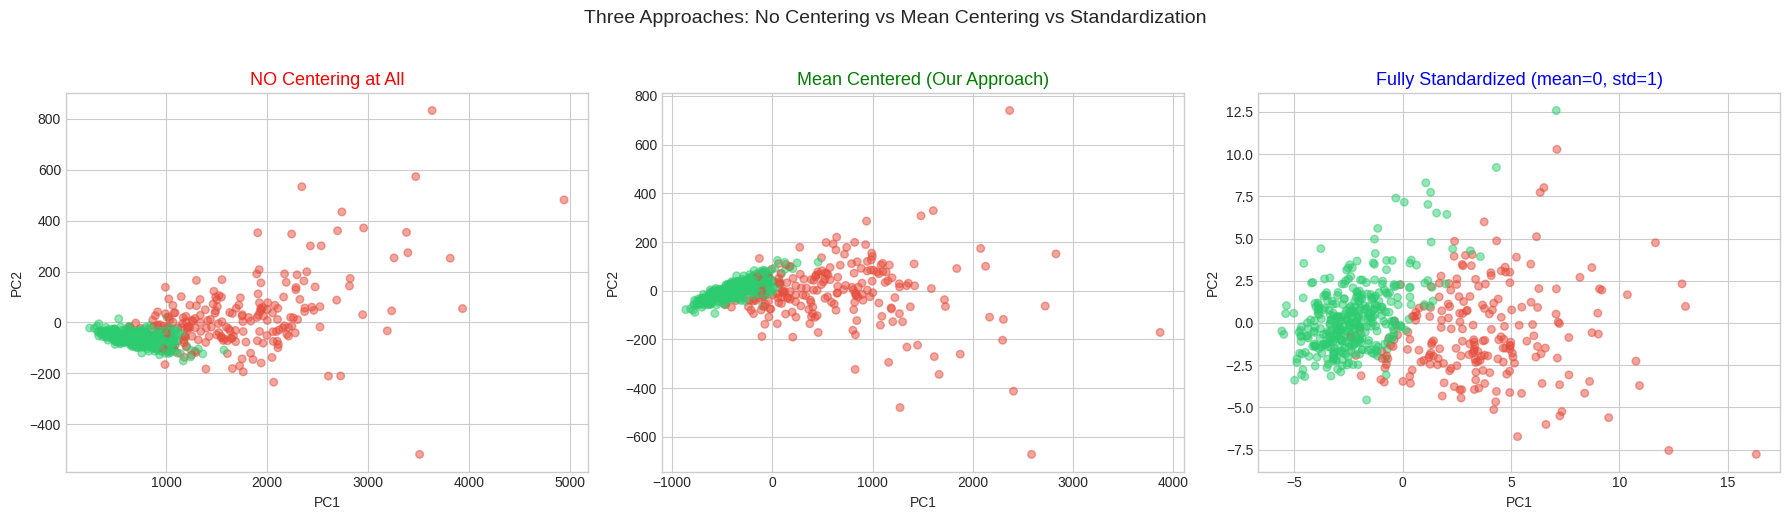

Comparison:
- NO centering: PCA is dominated by the mean values, not variance patterns
- Mean centering: PCA captures the true variance structure of the data
- Standardization: All features contribute equally regardless of original scale

Mean centering is the MINIMUM requirement for PCA to work correctly.
Standardization is an optional additional step that changes what PCA finds.


In [ ]:
# What happens with NO centering vs mean centering vs full standardization?

# No centering at all
pca_no_center = PCA(n_components=2)
X_no_center = pca_no_center.fit_transform(X.values)  # sklearn auto-centers, so we trick it

# Manual: truly no centering
cov_no_center = (X.values.T @ X.values) / (len(X) - 1)  # No mean subtraction!
evals_nc, evecs_nc = np.linalg.eigh(cov_no_center)
idx_nc = np.argsort(evals_nc)[::-1]
X_truly_no_center = X.values @ evecs_nc[:, idx_nc[:2]]

# Mean centered (our approach)
pca_centered = PCA(n_components=2)
X_centered_viz = pca_centered.fit_transform(X.values)

# Standardized (traditional approach)
from sklearn.preprocessing import StandardScaler
X_std = StandardScaler().fit_transform(X.values)
pca_std = PCA(n_components=2)
X_std_viz = pca_std.fit_transform(X_std)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_truly_no_center[:, 0], X_truly_no_center[:, 1], c=colors, alpha=0.5, s=30)
axes[0].set_title('NO Centering at All', fontsize=13, color='red')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')

axes[1].scatter(X_centered_viz[:, 0], X_centered_viz[:, 1], c=colors, alpha=0.5, s=30)
axes[1].set_title('Mean Centered (Our Approach)', fontsize=13, color='green')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')

axes[2].scatter(X_std_viz[:, 0], X_std_viz[:, 1], c=colors, alpha=0.5, s=30)
axes[2].set_title('Fully Standardized (mean=0, std=1)', fontsize=13, color='blue')
axes[2].set_xlabel('PC1'); axes[2].set_ylabel('PC2')

plt.suptitle('Three Approaches: No Centering vs Mean Centering vs Standardization',
             fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

print('Comparison:')
print('- NO centering: PCA is dominated by the mean values, not variance patterns')
print('- Mean centering: PCA captures the true variance structure of the data')
print('- Standardization: All features contribute equally regardless of original scale')
print(f'\nMean centering is the MINIMUM requirement for PCA to work correctly.')
print(f'Standardization is an optional additional step that changes what PCA finds.')

### Pitfall 2: Applying PCA BEFORE train/test split (data leakage!)

In [ ]:
from sklearn.pipeline import Pipeline

# WRONG WAY: fit PCA on ALL data, then split
pca_wrong = PCA(n_components=10)
X_pca_wrong = pca_wrong.fit_transform(X.values)  # Fitted on ALL data!
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_pca_wrong, y, test_size=0.2, random_state=42)
lr_wrong = LogisticRegression(max_iter=5000, random_state=42)
lr_wrong.fit(X_train_w, y_train_w)
acc_wrong = lr_wrong.score(X_test_w, y_test_w)

# RIGHT WAY: use Pipeline (fit PCA only on training data)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Note: PCA does mean centering internally, so no scaler needed here
pipeline = Pipeline([
    ('pca', PCA(n_components=10)),
    ('classifier', LogisticRegression(max_iter=5000, random_state=42))
])
pipeline.fit(X_train_r, y_train_r)
acc_right = pipeline.score(X_test_r, y_test_r)

print('PCA + Train/Test Split: The Right Way vs Wrong Way')
print('='*55)
print(f'WRONG (PCA on all data, then split): {acc_wrong*100:.1f}%')
print(f'RIGHT (Pipeline, PCA fit on train only): {acc_right*100:.1f}%')
print(f'\nThe wrong way may give slightly inflated results because')
print(f'the PCA transformation "saw" the test data during fitting.')
print(f'\nALWAYS use sklearn Pipeline to avoid data leakage!')

print(f'\n\nCorrect Pipeline code (with mean centering only):')
print('''
from sklearn.pipeline import Pipeline

# sklearn PCA internally mean-centers the data,
# so no separate StandardScaler is needed.
pipeline = Pipeline([
    ('pca', PCA(n_components=10)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)
''')

PCA + Train/Test Split: The Right Way vs Wrong Way
WRONG (PCA on all data, then split): 95.6%
RIGHT (Pipeline, PCA fit on train only): 95.6%

The wrong way may give slightly inflated results because
the PCA transformation "saw" the test data during fitting.

ALWAYS use sklearn Pipeline to avoid data leakage!


Correct Pipeline code (with mean centering only):

from sklearn.pipeline import Pipeline

# sklearn PCA internally mean-centers the data,
# so no separate StandardScaler is needed.
pipeline = Pipeline([
    ('pca', PCA(n_components=10)),
    ('classifier', LogisticRegression())
])

pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)



---
## 12. Summary Cheat Sheet

### How PCA Works:
1. **Mean-center** the data (subtract the mean of each feature)
2. Compute covariance matrix
3. Find eigenvalues/eigenvectors
4. Sort by eigenvalue (most variance first)
5. Pick top k components
6. Project data onto new axes

### Mean Centering vs Standardization:
- **Mean centering** (what we used): subtracts the mean only → preserves original variance structure → features with larger natural variance have more influence
- **Standardization**: subtracts mean AND divides by std → all features treated equally → use when features are on very different scales and you want equal contribution
- **sklearn's PCA()** does mean centering internally — no need for a separate step

### When to Use PCA:
- Many correlated features
- Need to visualize high-dimensional data
- Want to speed up training
- Combat curse of dimensionality (features > samples)

### Choosing Components:
- Keep 90-95% of explained variance
- Use the scree plot elbow method
- Cross-validate with different numbers

### Best Models After PCA:
- Logistic Regression, SVM, KNN, Neural Networks
- Avoid PCA with tree-based models (RF, XGBoost)

### Common Pitfalls:
- Not centering the data at all
- Data leakage (fitting PCA on test data)
- Using too few components
- Using PCA when interpretability is needed

In [ ]:
print('='*50)
print('    Thank you! Happy Learning!')
print('='*50)

    Thank you! Happy Learning!
